In [ ]:
# Artifical Intelligence Semester Project
# Car Mileage Predictor

In [ ]:
# Importing libraries

# Numerical libraries
import numpy as np

# To handle data in form of rows and columns
import pandas as pd

# Import linear regression machine learning library
from sklearn.linear_model import LinearRegression

# Importing ploting graphs libraries
import matplotlib.pyplot as plt

# To import statsmodel
import statsmodels.formula.api as smf

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import r2_score

In [ ]:
# Loading dataset
df = pd.read_csv('dataset.csv')

In [ ]:
# Displaying the dataset
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
# Describing the dataset
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.876884,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,39.171166,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,128.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,235.000000,5140.000000,24.800000,82.000000,3.000000


In [ ]:
# Getting info on Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    int64  
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(5), object(1)
memory usage: 28.1+ KB


In [ ]:
# Corelation of the variables
corr_table = df.corr()
corr_table

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
mpg,1.000000,-0.775396,-0.804203,-0.758824,-0.831741,0.420289,0.579267,0.563450
cylinders,-0.775396,1.000000,0.950721,0.810377,0.896017,-0.505419,-0.348746,-0.562543
displacement,-0.804203,0.950721,1.000000,0.865830,0.932824,-0.543684,-0.370164,-0.609409
horsepower,-0.758824,0.810377,0.865830,1.000000,0.835768,-0.666841,-0.408728,-0.454827
weight,-0.831741,0.896017,0.932824,0.835768,1.000000,-0.417457,-0.306564,-0.581024
acceleration,0.420289,-0.505419,-0.543684,-0.666841,-0.417457,1.000000,0.288137,0.205873
model year,0.579267,-0.348746,-0.370164,-0.408728,-0.306564,0.288137,1.000000,0.180662
origin,0.563450,-0.562543,-0.609409,-0.454827,-0.581024,0.205873,0.180662,1.000000


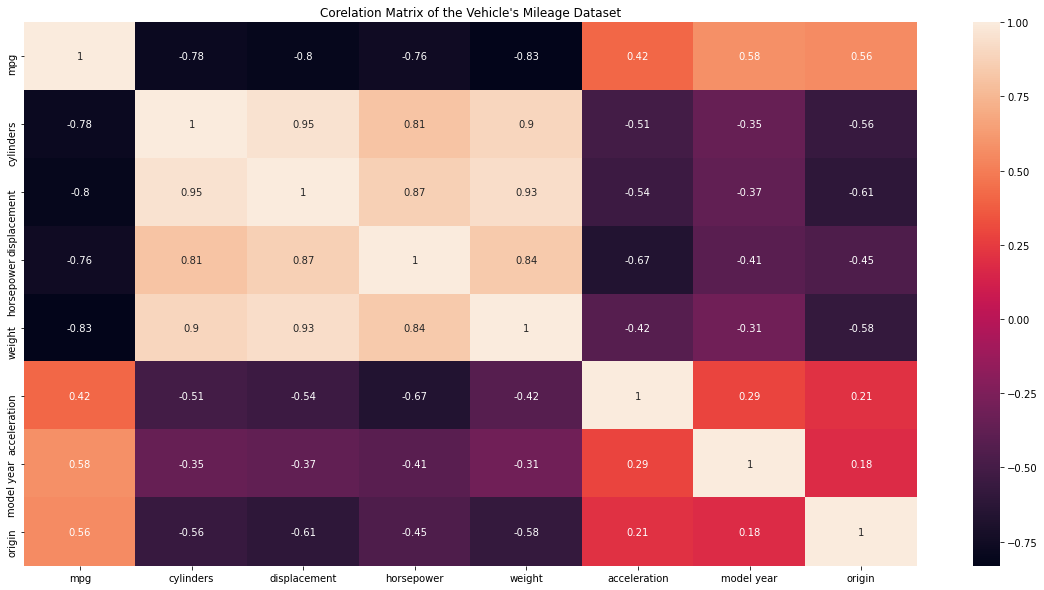

In [ ]:
# 'mpg' column is having good corelation on 'cylinders', 'displacement', 'weight'
# 'cylinder', 'displacement' and 'weight' and 'horsepower' are having negative corelation
plt.figure(figsize = (20,10))
g = sns.heatmap(corr_table,annot = True)
g.set(title = "Corelation Matrix of the Vehicle's Mileage Dataset")
plt.show()

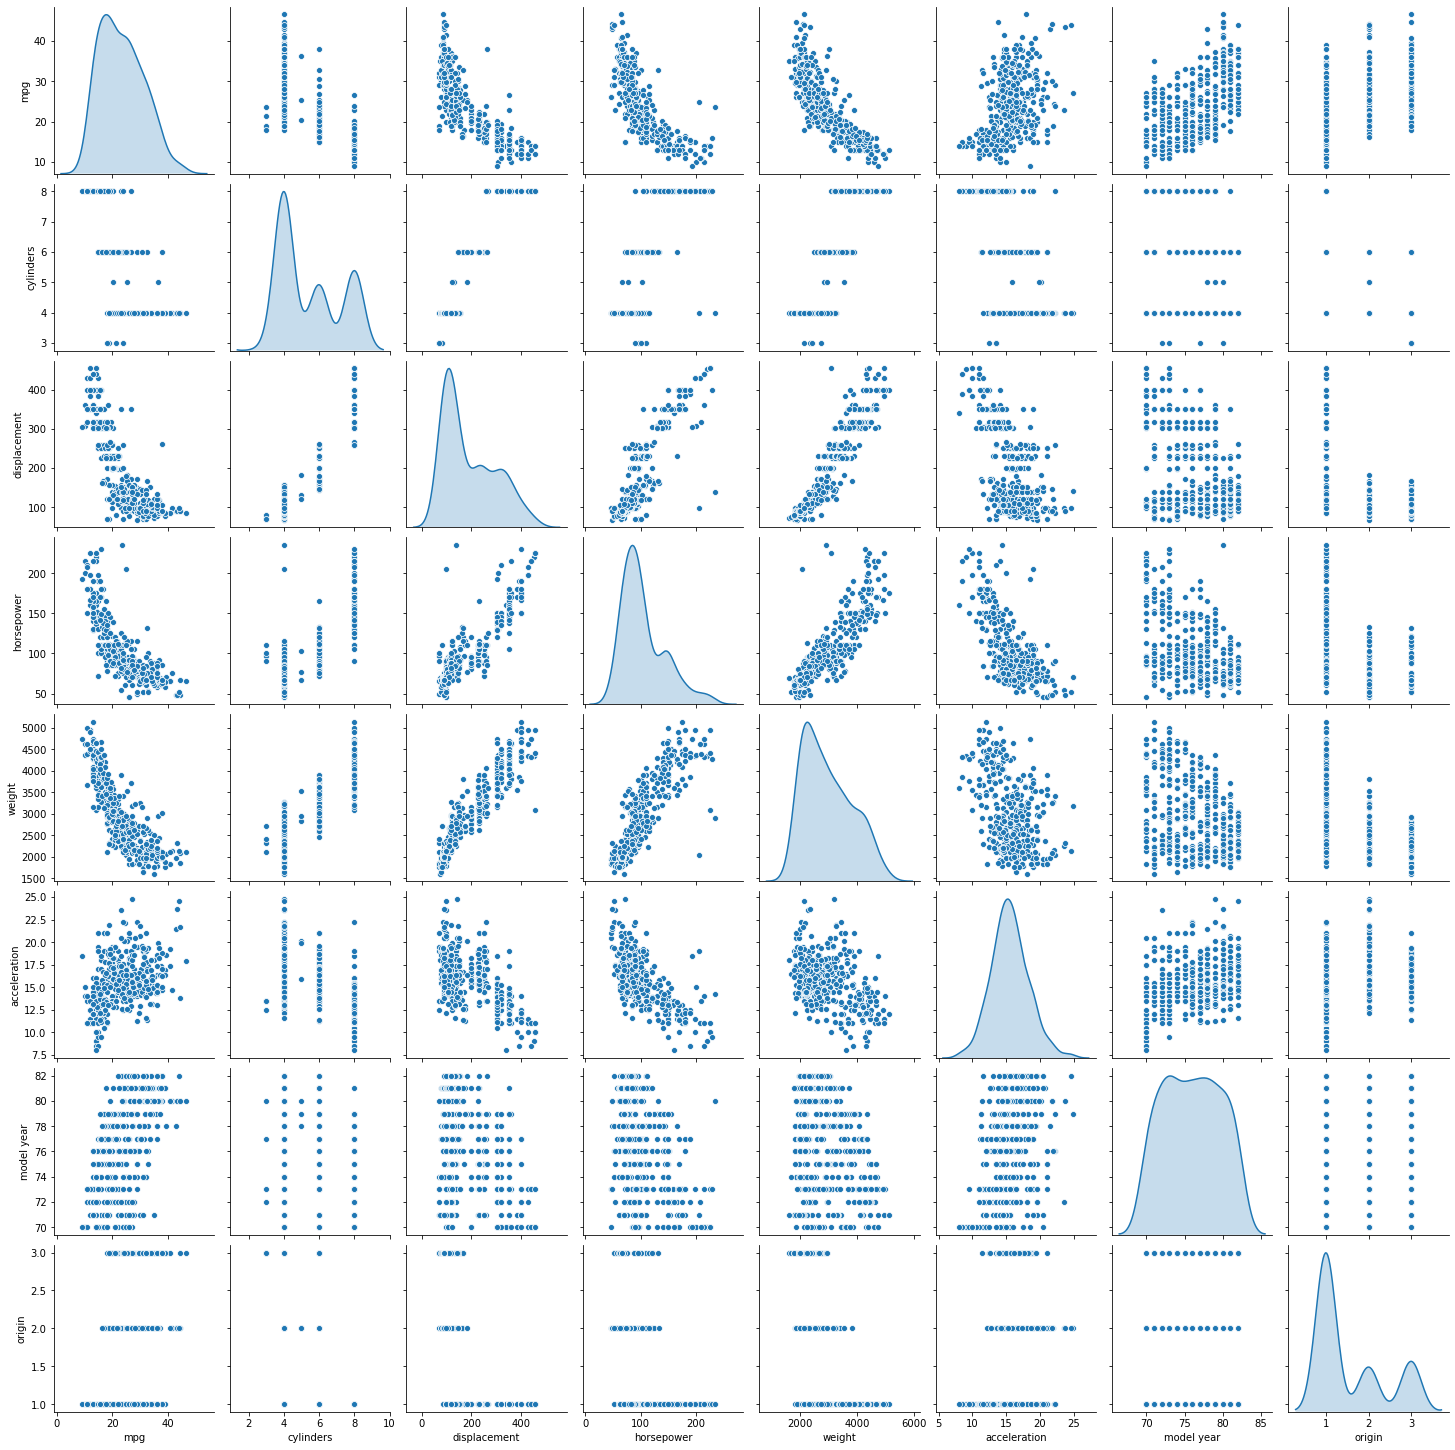

In [ ]:
# Data distribution
sns.pairplot(df, diag_kind = 'kde')
plt.show()

In [ ]:
# Statistical test to find the significance of variable so that we can reduce number of variables
test_1 = smf.ols('mpg ~ cylinders + displacement + horsepower + weight + acceleration + origin', df).fit()
test_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.718
Model:                            OLS   Adj. R-squared:                  0.714
Method:                 Least Squares   F-statistic:                     165.9
Date:                Wed, 16 Dec 2020   Prob (F-statistic):          3.50e-104
Time:                        18:13:45   Log-Likelihood:                -1130.7
No. Observations:                 398   AIC:                             2275.
Df Residuals:                     391   BIC:                             2303.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       42.2318      2.598     16.254      0.000      37.124      47.340
cylinders       -0.5210      0.403     -1.292      0.197      -1.314       0.272
displacement     0.0086      0.009      0.940      0.348      -0.009       0.027
horsepower      -0.0442      0.013     -3.377      0.001      -0.070      -0.018
weight          -0.0052      0.001     -6.778      0.000      -0.007      -0.004
acceleration     0.0362      0.114      0.318      0.751      -0.188       0.260
origin           1.3313      0.340      3.919      0.000       0.663       1.999
==============================================================================
Omnibus:                       30.805   Durbin-Watson:                   0.882
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               40.386
Skew:                           0.601   Prob(JB):                     1.70e-09
Kurtosis:                       3.995   Cond. No.                     3.85e+04
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.85e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
# Cleaning the dataset
# 'P' value of 'acceleration' is greater than 0.05
# Remove the 'acceleration' variable from the dataset
# Remove 'mpg' as it is target value
# Remove 'car name' as it is of no use
x = df.drop(columns = ['mpg', 'acceleration','car name'])
y = df['mpg']

In [ ]:
# Input dataset
x

,cylinders,displacement,horsepower,weight,model year,origin
0,8,307.0,130,3504,70,1
1,8,350.0,165,3693,70,1
2,8,318.0,150,3436,70,1
3,8,304.0,150,3433,70,1
4,8,302.0,140,3449,70,1
...,...,...,...,...,...,...
393,4,140.0,86,2790,82,1
394,4,97.0,52,2130,82,2
395,4,135.0,84,2295,82,1
396,4,120.0,79,2625,82,1


In [ ]:
# Output dataset
y

0      18.0
1      15.0
2      18.0
3      16.0
4      17.0
       ... 
393    27.0
394    44.0
395    32.0
396    28.0
397    31.0
Name: mpg, Length: 398, dtype: float64

In [ ]:
# Spiltting the dataset into training and testing Data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.20)

In [ ]:
# Create model
LR = LinearRegression()

In [ ]:
# Training the model
LR.fit(x_train,y_train)

LinearRegression()

In [ ]:
# Testing the model
# input_value = ([[8, 206, 200, 1900, 70, 2]])
predictions = LR.predict(x_test)

In [ ]:
# Calculate accuracy
accuracy = r2_score(y_test, predictions) * 100
print(f'Accuracy of your Model is {accuracy}%')

Accuracy of your Model is 79.72416502939545%


In [ ]:
# Input from the user and displaying result
values = [[8,206,200,1900,70,2]]
y_predict = LR.predict(values)
new_mileage = LR.predict(values)
print(f'Predicted Mileage of your Vechice is {new_mileage}')

Predicted Mileage of your Vechice is [24.95870078]
